# Analyses of the grid (PLAN.md, section 2.6)

This notebook reproduces the two figures and the table from the frozen grid
(git tag `grid-frozen`): 100 features, 40 texts each, 3 conditions (explanations A
and B, placebo), 5 scorers, 2 passes, 120,000 calls. It makes no API call.

The computation is in `src/autointerp/report.py`, shared with
`scripts/analyze_grid.py`. Intervals are 95% percentile intervals from a bootstrap
over features (10,000 resamples, seed 20261120). Every statistic uses the same
resampled features, so differences between scorers are paired.

In [1]:
import hashlib
import json

import pandas as pd

from autointerp import report
from autointerp.neuronpedia import ROOT

GRID = ROOT / "data" / "runs" / "grid"
summary = json.loads((GRID / "summary.json").read_text())
for name, digest in summary["sha256"].items():
    assert hashlib.sha256((GRID / name).read_bytes()).hexdigest() == digest, name
print("frozen grid files unchanged:", list(summary["sha256"]))

calls = report.load_grid()
print(len(calls), "calls,", calls.feature.nunique(), "features")

frozen grid files unchanged: ['calls.csv', 'calls.jsonl.gz']
120000 calls, 100 features


In [2]:
res = report.compute(calls)  # about 30 s: 10,000 resamples per statistic

## Check on placebo accuracy (rule 9)

Placebo accuracy is expected near 50%. Above 60% for a scorer, a form cue would be
looked for before any conclusion.

In [3]:
pd.DataFrame(
    {report.NAMES[s]: {c: 100 * v[c]["est"] for c in "ABP"} for s, v in res["accuracy"].items()}
).T.round(1).rename(columns={"P": "placebo"})

,A,B,placebo
Haiku 5.5,77.2,79.3,48.6
Sonnet 5.5,77.6,80.8,49.5
Opus 5.5,80.6,82.5,49.2
Gemini 2.5 Flash,77.2,80.9,49.4
Mistral Small 3.2,77.2,79.1,49.0


## Figure 1. Agreement between scorers (Analysis 1)

Raw agreement and Cohen's kappa per pair, conditions A and B pooled, pass 1, on the
texts both scorers answered with 1 or 0. High agreement says the scorers are
interchangeable on these texts, not that they are right: part of it comes from both
being often right.

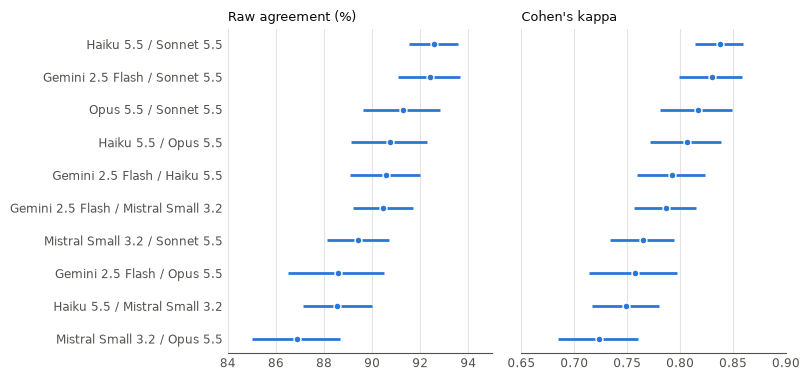

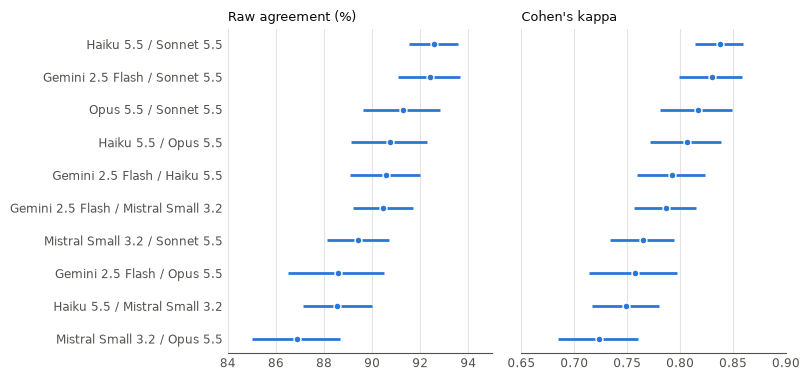

In [4]:
report.fig_agreement(res)

In [5]:
def agreement_table(block):
    return (
        pd.DataFrame(
            {
                k: {
                    "n": v["n"],
                    "agreement %": 100 * v["agreement"]["est"],
                    "kappa": v["kappa"]["est"],
                    "kappa lo": v["kappa"]["lo"],
                    "kappa hi": v["kappa"]["hi"],
                }
                for k, v in block.items()
            }
        )
        .T.sort_values("kappa", ascending=False)
        .round(3)
    )


agreement_table(res["agreement_AB_pass1"])

,n,agreement %,kappa,kappa lo,kappa hi
haiku-5.5 / sonnet-5.5,7905.0,92.57,0.838,0.814,0.859
gemini-flash / sonnet-5.5,7964.0,92.40,0.830,0.799,0.858
opus-5.5 / sonnet-5.5,7882.0,91.30,0.816,0.781,0.849
haiku-5.5 / opus-5.5,7818.0,90.76,0.806,0.772,0.838
gemini-flash / haiku-5.5,7897.0,90.59,0.792,0.759,0.823
gemini-flash / mistral-small,7941.0,90.47,0.786,0.756,0.815
mistral-small / sonnet-5.5,7947.0,89.40,0.765,0.734,0.794
gemini-flash / opus-5.5,7875.0,88.57,0.758,0.714,0.797
haiku-5.5 / mistral-small,7880.0,88.55,0.749,0.716,0.780
mistral-small / opus-5.5,7861.0,86.87,0.723,0.684,0.760


Check (rule 6): the same on pass 2, and under the placebo (reported apart: nearly
every answer is 0 there, which inflates raw agreement).

In [6]:
pd.DataFrame(
    {
        "kappa pass 1": agreement_table(res["agreement_AB_pass1"])["kappa"],
        "kappa pass 2": agreement_table(res["agreement_AB_pass2"])["kappa"],
        "placebo agreement %": agreement_table(res["agreement_P_pass1"])["agreement %"],
        "placebo kappa": agreement_table(res["agreement_P_pass1"])["kappa"],
    }
)

,kappa pass 1,kappa pass 2,placebo agreement %,placebo kappa
gemini-flash / haiku-5.5,0.792,0.791,98.76,0.674
gemini-flash / mistral-small,0.786,0.787,98.66,0.612
gemini-flash / opus-5.5,0.758,0.760,98.15,0.593
gemini-flash / sonnet-5.5,0.830,0.832,99.00,0.672
haiku-5.5 / mistral-small,0.749,0.748,98.41,0.595
haiku-5.5 / opus-5.5,0.806,0.805,98.20,0.638
haiku-5.5 / sonnet-5.5,0.838,0.831,98.86,0.675
mistral-small / opus-5.5,0.723,0.725,97.68,0.500
mistral-small / sonnet-5.5,0.765,0.762,98.56,0.537
opus-5.5 / sonnet-5.5,0.816,0.820,98.37,0.613


## Figure 2. Gain over the placebo (Analysis 2, central measure)

Gain = mean of the accuracies with A and with B, minus the accuracy with the
placebo, in percentage points. Panel (b) gives the 10 paired differences. With 10
comparisons at 95%, about one difference in two series of comparisons would exclude
0 by chance (PLAN.md 2.6, rule 2).

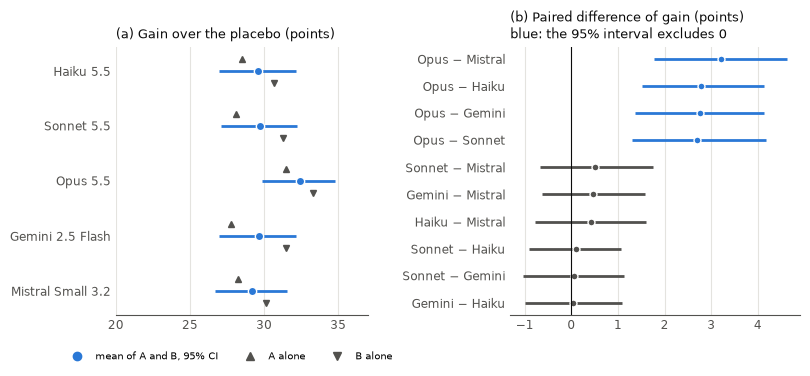

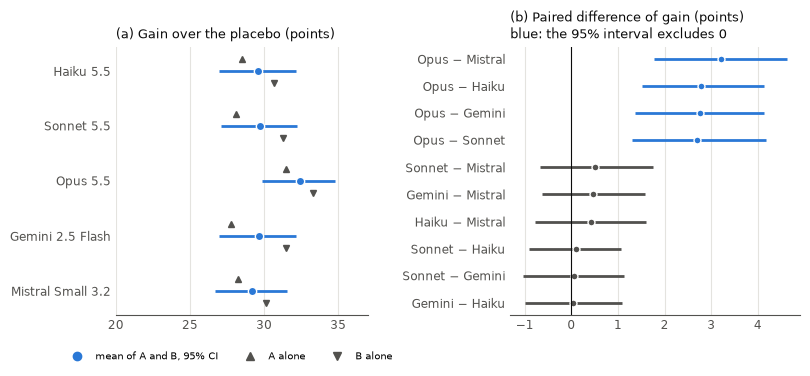

In [7]:
report.fig_gain(res)

In [8]:
gains = pd.DataFrame(
    {
        report.NAMES[s]: {
            f"{k} {b}": 100 * v[k][b] for k in ("AB", "A", "B") for b in ("est", "lo", "hi")
        }
        for s, v in res["gain"].items()
    }
).T.round(1)
diffs = pd.DataFrame(
    {k: {b: 100 * v[b] for b in ("est", "lo", "hi")} for k, v in res["gain_differences"].items()}
).T.round(1)
diffs["excludes 0"] = (diffs["lo"] > 0) | (diffs["hi"] < 0)
display(gains)
diffs

,AB est,AB lo,AB hi,A est,A lo,A hi,B est,B lo,B hi
Haiku 5.5,29.6,26.9,32.2,28.5,25.4,31.6,30.7,27.8,33.4
Sonnet 5.5,29.7,27.1,32.2,28.1,24.9,31.2,31.3,28.6,33.9
Opus 5.5,32.4,29.8,34.8,31.4,28.4,34.4,33.3,30.7,35.8
Gemini 2.5 Flash,29.6,26.9,32.2,27.8,24.6,30.8,31.5,28.6,34.3
Mistral Small 3.2,29.2,26.7,31.6,28.2,25.3,31.1,30.1,27.4,32.8


,est,lo,hi,excludes 0
haiku-5.5 - sonnet-5.5,-0.1,-1.1,0.9,False
haiku-5.5 - opus-5.5,-2.8,-4.1,-1.5,True
haiku-5.5 - gemini-flash,-0.0,-1.1,1.0,False
haiku-5.5 - mistral-small,0.4,-0.8,1.6,False
sonnet-5.5 - opus-5.5,-2.7,-4.2,-1.3,True
sonnet-5.5 - gemini-flash,0.0,-1.0,1.1,False
sonnet-5.5 - mistral-small,0.5,-0.7,1.7,False
opus-5.5 - gemini-flash,2.8,1.4,4.1,True
opus-5.5 - mistral-small,3.2,1.8,4.6,True
gemini-flash - mistral-small,0.5,-0.6,1.6,False


## Table. Profile per scorer (Analysis 3)

Sensitivity (share of positives answered 1), specificity (share of negatives
answered 0), rate of 1 answers and invalid answers, in %, mean over both passes;
share of texts answered differently by the two passes. Stability between passes is
not a ceiling on agreement between scorers.

In [9]:
report.profile_table(res)

,scorer,condition,sensitivity,specificity,rate of 1,invalid,changed between passes
0,Haiku 5.5,A,62.1,92.2,34.5,1.01,3.1
1,Haiku 5.5,B,67.1,91.5,37.2,1.18,3.1
2,Haiku 5.5,placebo,1.5,95.9,2.1,1.34,3.1
3,Sonnet 5.5,A,60.3,94.9,32.6,0.19,1.4
4,Sonnet 5.5,B,67.4,94.2,36.5,0.24,1.4
5,Sonnet 5.5,placebo,1.1,98.0,1.4,0.18,1.4
6,Opus 5.5,A,71.2,90.1,40.4,1.11,2.3
7,Opus 5.5,B,75.0,90.0,42.4,1.44,2.3
8,Opus 5.5,placebo,2.1,96.2,2.9,0.13,2.3
9,Gemini 2.5 Flash,A,58.7,95.7,31.4,0.25,0.2


## Outputs

The same files as `scripts/analyze_grid.py`, checked against the committed results.

results identical to the committed ones; figures and table written


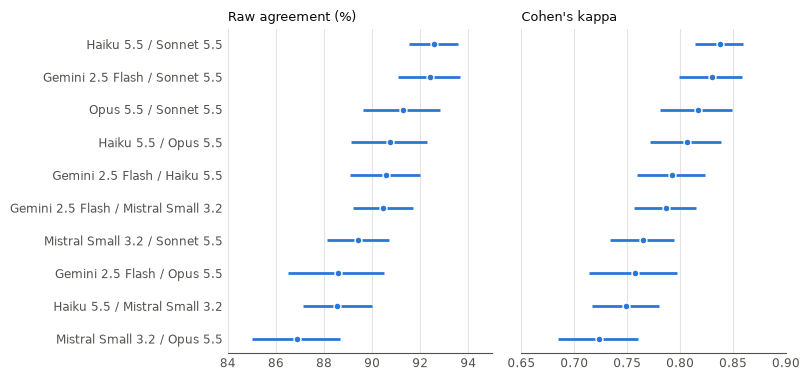

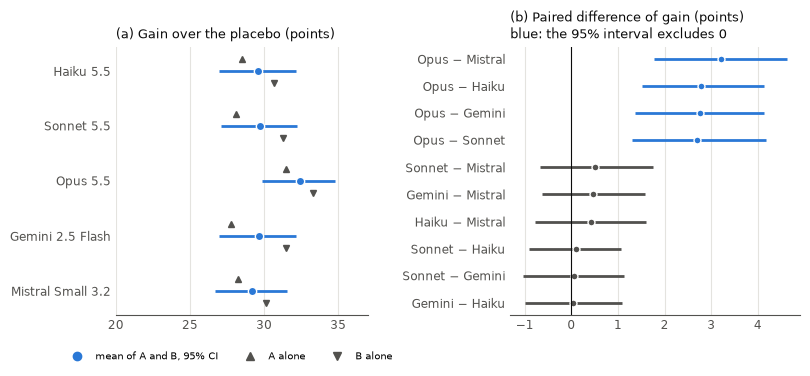

In [10]:
out = ROOT / "data" / "analysis"
committed = json.loads((out / "results.json").read_text())
assert committed == json.loads(json.dumps(res)), "results differ from data/analysis/results.json"
report.profile_table(res).to_csv(out / "table_profile.csv", index=False)
report.fig_agreement(res).savefig(ROOT / "figures" / "figure1_agreement.png", dpi=200)
report.fig_gain(res).savefig(ROOT / "figures" / "figure2_gain.png", dpi=200)
print("results identical to the committed ones; figures and table written")

## Exploratory: agreement on errors (added after the freeze, DEVIATIONS.md, 1)

Decided after the pilot, before any grid result was read, and not part of the frozen
plan: read it as exploratory. For each pair, the share of texts where both scorers
are wrong, over what independent errors would give (e_x × e_y). A ratio above 1
means the two scorers fail on the same texts. Every pair is expected above 1,
because some texts are hard for every scorer, so the comparison that matters is
within Claude against across families. It rests on 3 pairs against 7, and family is
mixed with settings.

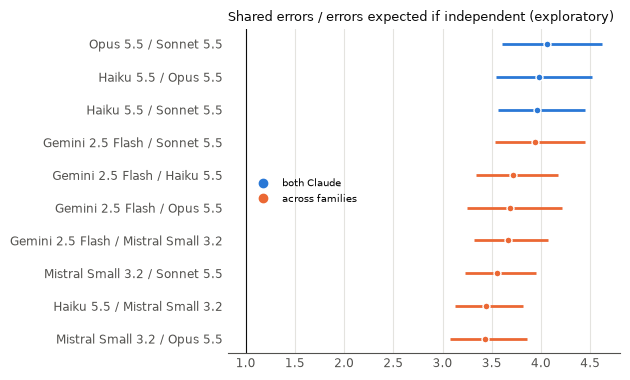

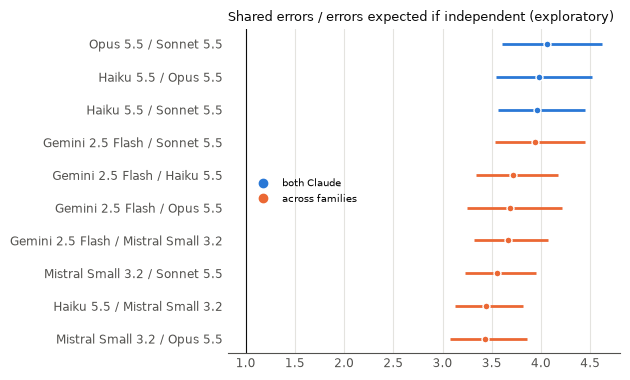

In [11]:
exp = report.exploratory_errors(calls)
report.fig_errors(exp)

In [12]:
pd.DataFrame(
    {
        k: {
            "both Claude": k in exp["within_claude"],
            "e_x %": 100 * v["e_x"],
            "e_y %": 100 * v["e_y"],
            "shared %": 100 * v["e_xy"],
            "if independent %": 100 * v["e_x"] * v["e_y"],
            "ratio": v["ratio"]["est"],
            "lo": v["ratio"]["lo"],
            "hi": v["ratio"]["hi"],
        }
        for k, v in exp["pairs"].items()
    }
).T.sort_values("ratio", ascending=False).round(2)

,both Claude,e_x %,e_y %,shared %,if independent %,ratio,lo,hi
opus-5.5 / sonnet-5.5,True,17.55,20.77,14.81,3.645135,4.0629,3.6053,4.6217
haiku-5.5 / opus-5.5,True,21.0,17.52,14.65,3.6792,3.9793,3.5405,4.5154
haiku-5.5 / sonnet-5.5,True,20.92,20.56,17.03,4.301152,3.9587,3.5608,4.444
gemini-flash / sonnet-5.5,False,20.83,20.59,16.91,4.288897,3.9428,3.5325,4.4437
gemini-flash / haiku-5.5,False,20.75,20.89,16.12,4.334675,3.7173,3.3372,4.1758
gemini-flash / opus-5.5,False,20.83,17.57,13.49,3.659831,3.6846,3.2522,4.2109
gemini-flash / mistral-small,False,20.84,21.41,16.36,4.461844,3.6664,3.3234,4.0734
mistral-small / sonnet-5.5,False,21.47,20.66,15.77,4.435702,3.5547,3.2261,3.9479
haiku-5.5 / mistral-small,False,21.0,21.38,15.47,4.4898,3.4445,3.1282,3.8215
mistral-small / opus-5.5,False,21.38,17.62,12.94,3.767156,3.4338,3.0792,3.8568


mean ratio within Claude minus across families: {'est': np.float64(0.3654), 'lo': 0.2302, 'hi': 0.5245}


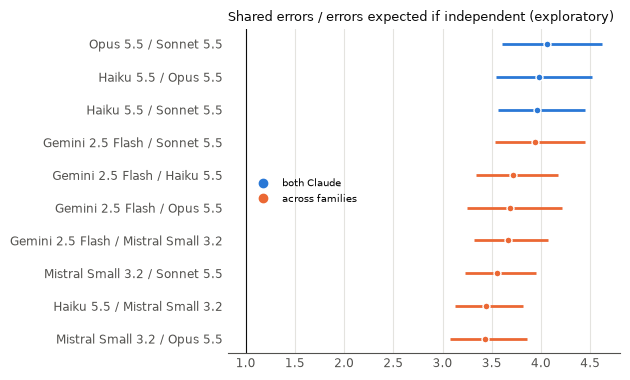

In [13]:
print("mean ratio within Claude minus across families:", exp["within_minus_across"])
committed = json.loads((out / "exploratory_errors.json").read_text())
assert committed == json.loads(json.dumps(exp)), (
    "differs from data/analysis/exploratory_errors.json"
)
report.fig_errors(exp).savefig(ROOT / "figures" / "exploratory_errors.png", dpi=200)

## Exploratory: do scorers rank explanations alike? (DEVIATIONS.md, 2)

Decided after the results. For each scorer, the accuracy of each of the 200
explanations (100 features, A and B). Per pair of scorers: the Spearman correlation of
these scores, and how often the two scorers pick the same explanation, the opposite
one, or a tie for at least one of them. The reference is each scorer against itself,
pass 1 against pass 2.

In [14]:
rank = report.exploratory_ranking(calls)
pd.DataFrame(
    {
        k: {
            "spearman": v["spearman"]["est"],
            "lo": v["spearman"]["lo"],
            "hi": v["spearman"]["hi"],
            "same": v["same"],
            "opposite": v["opposite"],
            "tie": v["tie"],
            "opposite share lo": v["opposite_share"]["lo"],
            "opposite share hi": v["opposite_share"]["hi"],
        }
        for k, v in rank["pairs"].items()
    }
).T

,spearman,lo,hi,same,opposite,tie,opposite share lo,opposite share hi
haiku-5.5 / sonnet-5.5,0.8951,0.8470,0.9296,69.0,13.0,18.0,0.07,0.20
haiku-5.5 / opus-5.5,0.8345,0.7496,0.8966,63.0,23.0,14.0,0.15,0.32
haiku-5.5 / gemini-flash,0.8763,0.8255,0.9123,67.0,15.0,18.0,0.08,0.22
haiku-5.5 / mistral-small,0.8540,0.7998,0.8932,63.0,20.0,17.0,0.12,0.28
sonnet-5.5 / opus-5.5,0.8335,0.7418,0.9028,64.0,19.0,17.0,0.12,0.27
sonnet-5.5 / gemini-flash,0.8935,0.8415,0.9306,65.0,14.0,21.0,0.08,0.21
sonnet-5.5 / mistral-small,0.8344,0.7654,0.8864,61.0,15.0,24.0,0.08,0.22
opus-5.5 / gemini-flash,0.8057,0.7175,0.8689,56.0,27.0,17.0,0.18,0.36
opus-5.5 / mistral-small,0.7645,0.6755,0.8326,59.0,22.0,19.0,0.14,0.30
gemini-flash / mistral-small,0.8692,0.8098,0.9112,60.0,18.0,22.0,0.11,0.26


In [15]:
print(
    "features where at least two scorers pick opposite explanations:",
    rank["features_with_opposite_choices"],
)
pd.DataFrame(rank["same_scorer_two_passes"]).T

features where at least two scorers pick opposite explanations: 47


,same,opposite,tie
haiku-5.5,72,6,22
sonnet-5.5,72,1,27
opus-5.5,69,7,24
gemini-flash,82,0,18
mistral-small,85,0,15


## Robustness: simultaneous intervals for the gain differences (DEVIATIONS.md, 3)

Bonferroni intervals, each at 99.5%, so that the 10 differences hold together at 95%.

In [16]:
simul = report.gain_differences_simultaneous(calls)
d = pd.DataFrame(
    {k: {b: 100 * v[b] for b in ("est", "lo", "hi")} for k, v in simul.items()}
).T.round(1)
d["excludes 0"] = (d["lo"] > 0) | (d["hi"] < 0)
for name, obj in (("exploratory_ranking", rank), ("gain_differences_simultaneous", simul)):
    committed = json.loads((out / f"{name}.json").read_text())
    assert committed == json.loads(json.dumps(obj)), f"differs from data/analysis/{name}.json"
d

,est,lo,hi,excludes 0
haiku-5.5 - sonnet-5.5,-0.1,-1.4,1.3,False
haiku-5.5 - opus-5.5,-2.8,-4.7,-1.0,True
haiku-5.5 - gemini-flash,-0.0,-1.5,1.4,False
haiku-5.5 - mistral-small,0.4,-1.3,2.1,False
sonnet-5.5 - opus-5.5,-2.7,-4.9,-0.7,True
sonnet-5.5 - gemini-flash,0.0,-1.5,1.6,False
sonnet-5.5 - mistral-small,0.5,-1.2,2.3,False
opus-5.5 - gemini-flash,2.8,0.8,4.8,True
opus-5.5 - mistral-small,3.2,1.2,5.2,True
gemini-flash - mistral-small,0.5,-1.1,2.1,False
